#### 使用GPU降维聚类

- conda环境: /mnt/NexData_file/home/ztt/conda_env/rapids_singlecell_2412/

- 默认参数：
    n_hvg=2000
    n_neighbors=20
    n_pcs=15
    res=0.5

In [7]:
import os
import random
random.seed(0)
import cupy as cp
import scanpy as sc
import numpy as np
import pandas as pd
import seaborn as sns
import rapids_singlecell as rsc
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context

import warnings
warnings.filterwarnings("ignore")

plt.style.use('default')  # 使用默认样式
plt.rcParams['figure.facecolor'] = 'white'  # 确保图像背景为白色
sc.settings.set_figure_params(dpi=100, dpi_save=200, figsize=(5, 5), facecolor='white')

import rmm
from rmm.allocators.cupy import rmm_cupy_allocator
rmm.reinitialize(
    managed_memory=True,  # Allows oversubscription
    pool_allocator=False, # default is False
    devices=0,            # GPU device IDs to register. By default registers only GPU 0.
)
cp.cuda.set_allocator(rmm_cupy_allocator)

In [8]:
def cluster_gpu(
    adata,
    n_hvg=2000,
    n_neighbors=20,
    n_pcs=15,
    res=(0.5,),
    batch_key="sample",
    metric="cosine",
    min_dist=0.3,
    random_state=10,
    save_raw=True,
    regress_keys=("total_counts", "pct_counts_mt"),
    plot=True,
):
    """
    GPU-based Scanpy/RAPIDS single-cell or spatial clustering workflow.

    Main steps:
    1. Normalize + log1p
    2. HVG selection
    3. Scale + PCA
    4. Harmony batch correction
    5. Neighbors + UMAP + Leiden clustering
    """

    import scanpy as sc
    import rapids_singlecell as rsc
    from matplotlib.pyplot import rc_context

    # -----------------------------
    # 0. Basic checks
    # -----------------------------
    if batch_key not in adata.obs.columns:
        raise ValueError(f"batch_key='{batch_key}' not found in adata.obs")

    if isinstance(res, (float, int)):
        res = (res,)

    if adata.n_obs < 3:
        raise ValueError("adata has too few observations for PCA/neighbors clustering")

    n_neighbors = min(int(n_neighbors), adata.n_obs - 1)
    if n_neighbors < 2:
        raise ValueError("n_neighbors must be at least 2 after checking adata.n_obs")

    # -----------------------------
    # 1. Move to GPU
    # -----------------------------
    rsc.get.anndata_to_GPU(adata, convert_all=True)

    # -----------------------------
    # 2. Normalize + log1p
    # -----------------------------
    rsc.pp.normalize_total(adata, target_sum=1e4, inplace=True)
    rsc.pp.log1p(adata)

    # raw 保存全基因的 normalize/log1p 矩阵，后续 marker 用 use_raw=True 时不会只剩 HVG。
    # 空间点位特别多且只做聚类时，可以把 save_raw=False 省内存。
    if save_raw:
        rsc.get.anndata_to_CPU(adata, convert_all=True)
        adata.raw = adata.copy()
        rsc.get.anndata_to_GPU(adata)

    # -----------------------------
    # 3. HVG
    # -----------------------------
    rsc.pp.highly_variable_genes(
        adata,
        n_top_genes=n_hvg,
        flavor="seurat",
        batch_key=batch_key,
    )
    if "highly_variable" not in adata.var.columns:
        raise RuntimeError("HVG failed: adata.var['highly_variable'] not found.")

    n_hvg_real = int(adata.var["highly_variable"].sum())
    print(f"[Info] Selected HVGs: {n_hvg_real}")

    if n_hvg_real == 0:
        raise RuntimeError("HVG failed: selected 0 highly variable genes.")

    if n_hvg_real < 500:
        print("[Warning] HVG number is very low. Check filtering, normalization, or n_hvg setting.")

    # 关键：切片后必须 copy，避免 view 问题；后续回归/scale/PCA 只在 HVG 子集上做。
    adata = adata[:, adata.var["highly_variable"].values].copy()

    regress_keys = [k for k in regress_keys if k in adata.obs.columns]
    if regress_keys:
        print(f"[Info] Regressing out: {regress_keys}")
        rsc.pp.regress_out(adata, regress_keys)
    else:
        print("[Info] Skip regress_out: no requested covariates found in adata.obs")

    # -----------------------------
    # 4. Scale + PCA
    # -----------------------------
    rsc.pp.scale(adata, max_value=10)

    max_pcs = min(adata.n_obs - 1, adata.n_vars, 50)
    if n_pcs > max_pcs:
        print(f"[Warning] n_pcs={n_pcs} is too large. Reset to {max_pcs}.")
        n_pcs = max_pcs
    n_comps = min(max(n_pcs, 30), max_pcs)

    rsc.pp.pca(
        adata,
        n_comps=n_comps,
        random_state=random_state,
    )

    # PCA variance ratio 需要转 CPU 后画更稳
    rsc.get.anndata_to_CPU(adata, convert_all=True)

    if plot:
        sc.pl.pca_variance_ratio(
            adata,
            log=True,
            n_pcs=min(30, adata.obsm["X_pca"].shape[1]),
        )

    # -----------------------------
    # 5. Harmony
    # -----------------------------
    rsc.get.anndata_to_GPU(adata, convert_all=True)

    n_batches = adata.obs[batch_key].nunique()
    if n_batches > 1:
        rsc.pp.harmony_integrate(
            adata,
            key=batch_key,
        )

        if "X_pca_harmony" not in adata.obsm:
            raise RuntimeError("Harmony failed: adata.obsm['X_pca_harmony'] not found.")
        use_rep = "X_pca_harmony"
    else:
        print(f"[Info] Only one '{batch_key}' level found. Skip Harmony and use X_pca.")
        use_rep = "X_pca"

    # -----------------------------
    # 6. Neighbors + UMAP
    # -----------------------------
    rsc.pp.neighbors(
        adata,
        n_neighbors=n_neighbors,
        n_pcs=n_pcs,
        metric=metric,
        use_rep=use_rep,
        random_state=random_state,
    )

    rsc.tl.umap(
        adata,
        min_dist=min_dist,
        random_state=random_state,
    )

    # -----------------------------
    # 7. Leiden multi-resolution
    # -----------------------------
    for r in res:
        key = f"res_{r}"
        rsc.tl.leiden(
            adata,
            resolution=float(r),
            key_added=key,
            random_state=random_state,
        )

    # -----------------------------
    # 8. Move back to CPU
    # -----------------------------
    rsc.get.anndata_to_CPU(adata, convert_all=True)

    # -----------------------------
    # 9. Plot
    # -----------------------------
    if plot:
        n_cells = adata.n_obs

        # 点大小：点位越多越小
        if n_cells >= 120000:
            size = max(0.2, 120000 / n_cells * 5)
        else:
            size = max(1, 120000 / n_cells)

        color_list = [batch_key] + [f"res_{r}" for r in res]

        with rc_context({"figure.figsize": (6, 6)}):
            sc.pl.umap(
                adata,
                color=color_list,
                legend_loc="right margin",
                legend_fontsize=9,
                frameon=True,
                size=size,
                show=False,
            )

    return adata

[Info] Selected HVGs: 2000
[Info] Regressing out: ['total_counts', 'pct_counts_mt']


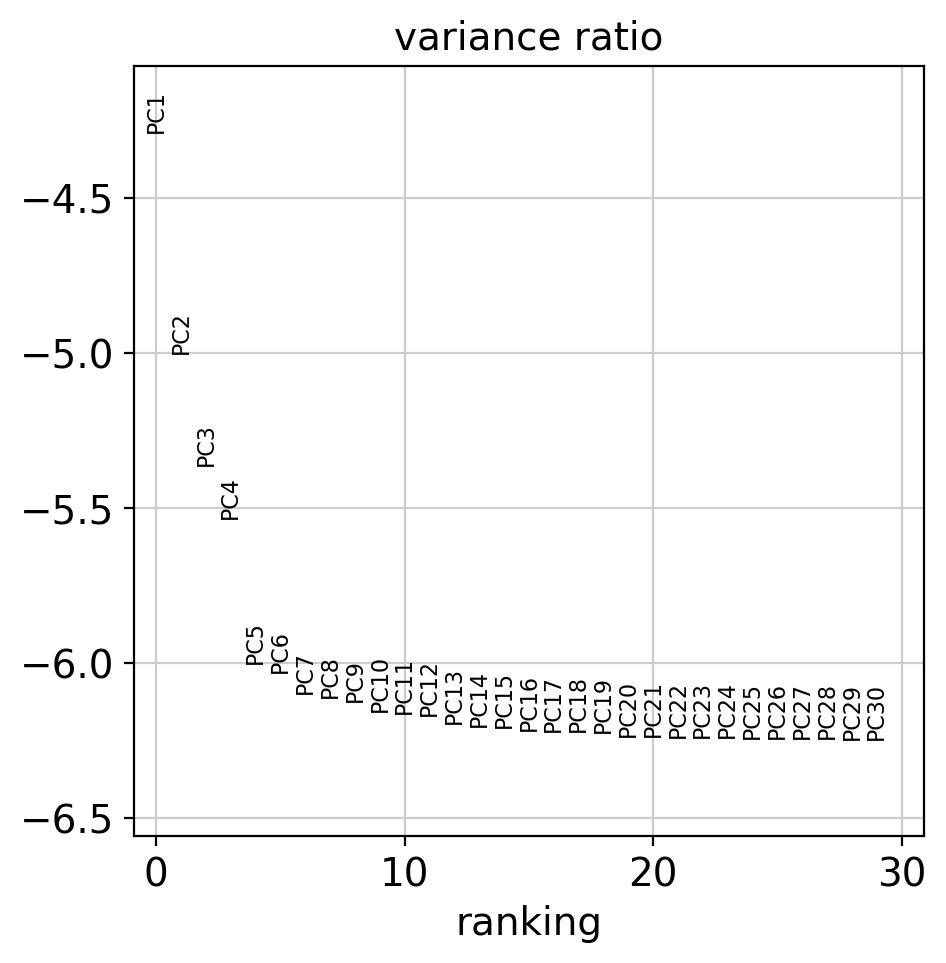

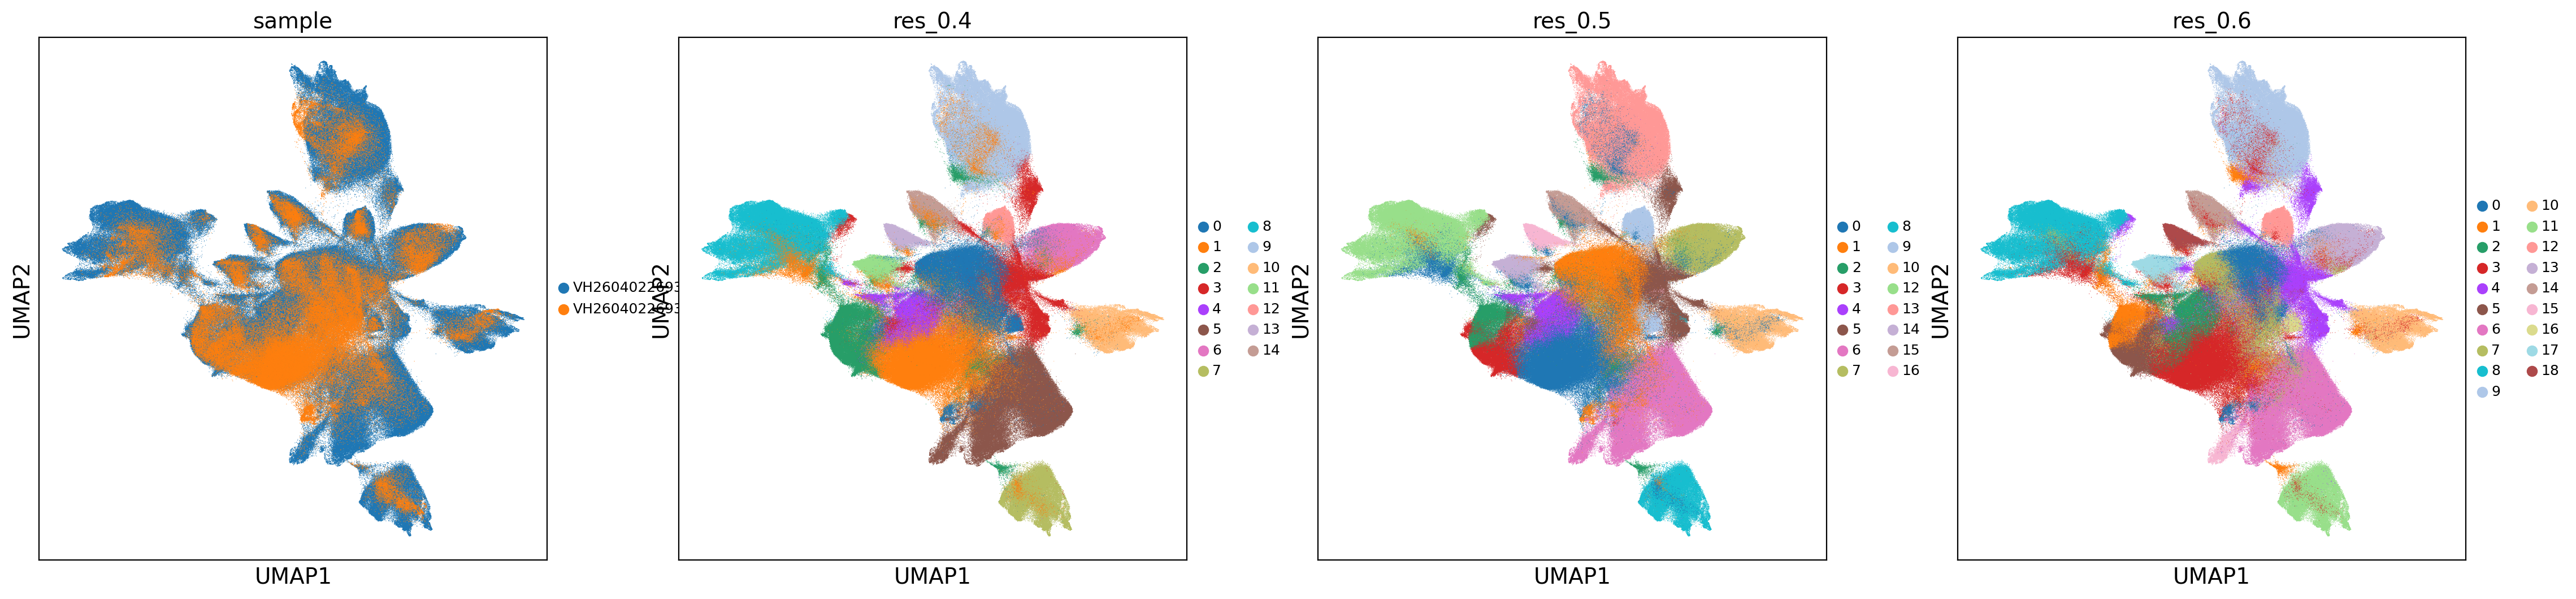

In [11]:
data_dir = '/home/hf/VH2604022693-01/OUT/data'
os.makedirs(data_dir, exist_ok=True)

adata = sc.read_h5ad(os.path.join(data_dir, 'adata_filtered.h5ad'))
adata = cluster_gpu(
    adata,
    n_hvg=2000,
    n_neighbors=20,
    n_pcs=15,
    res=(0.4,0.5,0.6),
    batch_key="sample",
    min_dist=0.2,
    save_raw=True,
)

adata.write(os.path.join(data_dir, 'adata_Cluster.h5ad'))

In [12]:
adata.obs['sample'].value_counts()

sample
VH2604022693-01_WT1    729775
VH2604022693-01_WT2    185433
Name: count, dtype: int64

In [13]:
adata.obs['sample'].unique().to_list()

['VH2604022693-01_WT1', 'VH2604022693-01_WT2']

In [14]:
adata.uns['spatial'].keys()

dict_keys(['VH2604022693-01_WT1', 'VH2604022693-01_WT2'])